In [2]:
import numpy as np
import matplotlib.pyplot as plt
from ekarus.e2e.devices.pyramid_wfs import PyramidWFS


[XuPy] GPU Acceleration not available. 
       Fallback to NumPy instead.


In [3]:
Npix = 120
sensorLambda = 750e-9
detector_size = Npix
oversampling = 4
pupilSizeInPixels = Npix
pupilSizeInM = 2
rebin = oversampling*pupilSizeInPixels/detector_size
subapertureSize = 40
subapPixSep = 48

apex_angle = 2*np.pi*sensorLambda/pupilSizeInM*(subapPixSep+subapertureSize)*rebin
pyr = PyramidWFS(apex_angle, oversampling, sensorLambda)

1.1478016056678602e-07 0.3966757257993868


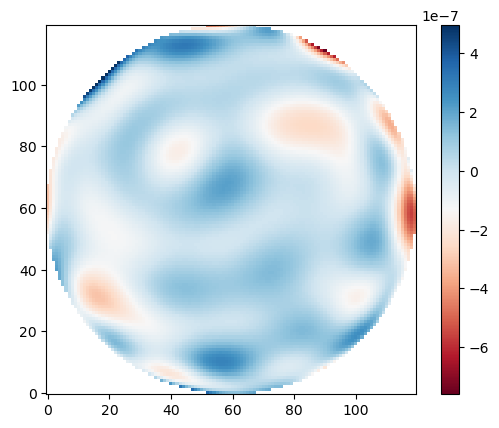

In [4]:

from arte.utils.zernike_generator import ZernikeGenerator
from arte.types.mask import CircularMask

def project_zernike_on_mask(mask, noll_ids:tuple, amplitudes:tuple):
    """
    Create a linear combination of Zernikes on a mask.
    
    :param mask: CircularMask object defining the pupil
    :param noll_ids: tuple of Zernike noll number
    :param amplitudes: Amplitude or tuple of amplitudes
                       of the Zernike aberration in radians
    
    :return: zernike combination
    """
    zg = ZernikeGenerator(mask)

    if isinstance(noll_ids,int):
        amp = amplitudes
        noll = noll_ids
        zern = amp * zg.getZernike(noll)
    else:
        amplitudes *= np.ones_like(noll_ids)
        zern = np.zeros(mask.mask().shape)
        for amp,noll in zip(amplitudes, noll_ids):
            zern += amp * zg.getZernike(noll)

    return zern


pupil = CircularMask((Npix,Npix), maskRadius=Npix//2, maskCenter=(Npix/2,Npix/2))
noll_ids = np.arange(2,100)
amplitudes = np.random.randn(len(noll_ids))/np.sqrt(np.sqrt(noll_ids))*3e-8
random_phase = project_zernike_on_mask(pupil, noll_ids, amplitudes)
rms = np.sqrt(np.mean(random_phase[pupil.asTransmissionValue().astype(bool)]**2))
SR = np.exp(-(rms/sensorLambda*2*np.pi)**2)
print(rms,SR)

plt.figure()
plt.imshow(np.ma.masked_array(random_phase,mask=pupil.mask()),origin='lower',cmap='RdBu')
plt.colorbar()

In [5]:
pyr.set_modulation_angle(4)
lambdaOverD = sensorLambda/pupilSizeInM
# pyr._modNsteps *= 4

Modulating 4 [lambda/D] with 28 modulation steps


In [6]:
def zero_padding(arr,oversampling:int):
    Ny, Nx = arr.shape
    pad_y = int(np.round((oversampling - 1) / 2 * Ny))
    pad_x = int(np.round((oversampling - 1) / 2 * Nx))
    padded = np.pad(arr, ((pad_y, pad_y), (pad_x, pad_x)), mode='constant', constant_values=0.0)
    return padded

# def pad_and_fft(arr, oversampling:int=oversampling, inverse:bool=False, crop:bool=True):
#     Ny, Nx = arr.shape
#     pad_y = int(np.round((oversampling - 1) / 2 * Ny))
#     pad_x = int(np.round((oversampling - 1) / 2 * Nx))
#     padded = np.pad(arr, ((pad_y, pad_y), (pad_x, pad_x)), mode='constant', constant_values=0.0)
#     if inverse:
#         fft_vec = np.fft.ifft2(np.fft.ifftshift(padded)) #np.fft.ifftshift(np.fft.ifft2(np.fft.ifftshift(padded)))
#     else:
#         fft_vec = np.fft.fftshift(np.fft.fft2(padded))
#     if crop:
#         return fft_vec[pad_y:pad_y + Ny, pad_x:pad_x + Nx]
#     else:
#         return fft_vec


def get_modulation_intensity(pyr, input_field, lambdaOverD, oversampling:int=oversampling):
    """
    Compute the GSC signal omega from the complex input field.
    """
    mul = 4
    alpha_pix = pyr.modulationAngleInLambdaOverD * (2 * np.pi)
    phi_vec = (2 * np.pi) * np.arange(pyr._modNsteps*mul) / (pyr._modNsteps*mul)
    pad_int = zero_padding(input_field,oversampling)
    intensity = np.zeros(pad_int.shape, dtype=np.float64)
    tiltX, tiltY = pyr._get_XY_tilt_planes(pad_int.shape)
    phase_delay = pyr.pyramid_phase_delay(pad_int.shape) / lambdaOverD / oversampling
    for phi in phi_vec:
        tilt = tiltX * np.cos(phi) + tiltY * np.sin(phi)
        tilted_input = pad_int * np.exp(1j * tilt * alpha_pix*oversampling, dtype=np.complex128)
        focal_field = np.fft.fftshift(np.fft.fft2(tilted_input))
        delayed_focal = focal_field * np.exp(1j * phase_delay, dtype=np.complex128)
        intensity += np.abs(delayed_focal)**2 / (pyr._modNsteps*mul)
    # intensity = np.fft.fftshift(intensity)
    total = np.sum(intensity)
    if total > 0:
        intensity /= total
    return intensity


def compute_impulse_response(omega, oversampling:int=oversampling):
    """
    Compute the impulse response corresponding to equation 13:
    IR = 2 * Im( conj(FFT(mask)) * FFT(mask * omega) )
    """
    # Ny, Nx = omega.shape
    # pad_y = int(np.round((oversampling - 1) / 2 * Ny))
    # pad_x = int(np.round((oversampling - 1) / 2 * Nx))
    # padded = np.pad(omega, ((pad_y, pad_y), (pad_x, pad_x)), 'constant', constant_values=0.0)
    # pyramid_phase = pyr.pyramid_phase_delay(padded.shape) / lambdaOverD / oversampling
    pyramid_phase = pyr.pyramid_phase_delay(omega.shape) / lambdaOverD / oversampling
    pyramid_mask = np.exp(1j*pyramid_phase,dtype=complex)
    # padded_pyr_mask = np.pad(pyramid_mask, ((pad_y, pad_y), (pad_x, pad_x)), 'constant', constant_values=0.0)
    mask_fft = np.fft.fft2(np.fft.ifftshift(pyramid_mask))
    masked_omega = pyramid_mask * omega#padded
    masked_fft = np.fft.fft2(np.fft.ifftshift(masked_omega))
    ir = 2 * np.imag(np.conj(mask_fft) * masked_fft)
    ir = np.fft.fftshift(ir)
    return ir

(220.0, 260.0)

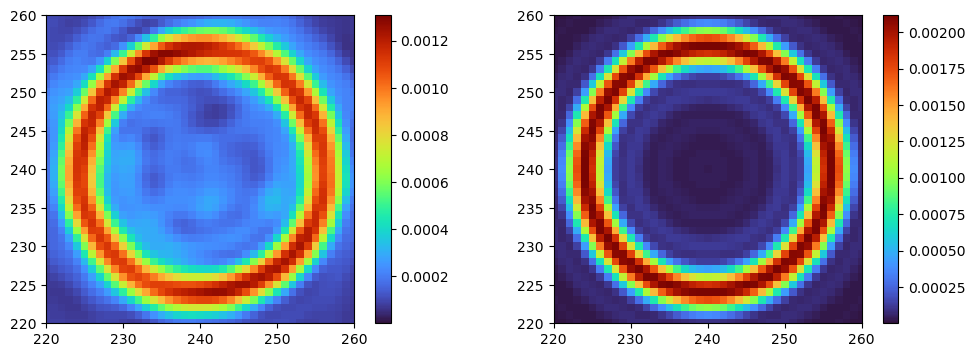

In [7]:

ref_ef = pupil.asTransmissionValue() * np.exp(1j*random_phase*0.0, dtype=complex)
omega_ref = get_modulation_intensity(pyr, ref_ef, lambdaOverD)

in_ef = pupil.asTransmissionValue() * np.exp(1j*random_phase*(2*np.pi)/sensorLambda, dtype=complex)
omega = get_modulation_intensity(pyr, in_ef, lambdaOverD)

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.imshow(omega,origin='lower',cmap='turbo')
plt.colorbar()
plt.xlim([220,260])
plt.ylim([220,260])
plt.subplot(1,2,2)
plt.imshow(omega_ref,origin='lower',cmap='turbo')
plt.colorbar()
plt.xlim([220,260])
plt.ylim([220,260])

In [8]:
# ratio = omega/omega_ref
# # ratio = np.fft.ifft2( pad_and_fft(omega) / pad_and_fft(omega_ref))
# ratio /= np.max(ratio)

# plt.figure()
# plt.imshow(np.abs(ratio),origin='lower',cmap='turbo')
# plt.colorbar()

In [9]:
ir = compute_impulse_response(omega)
ir_ref = compute_impulse_response(omega_ref)

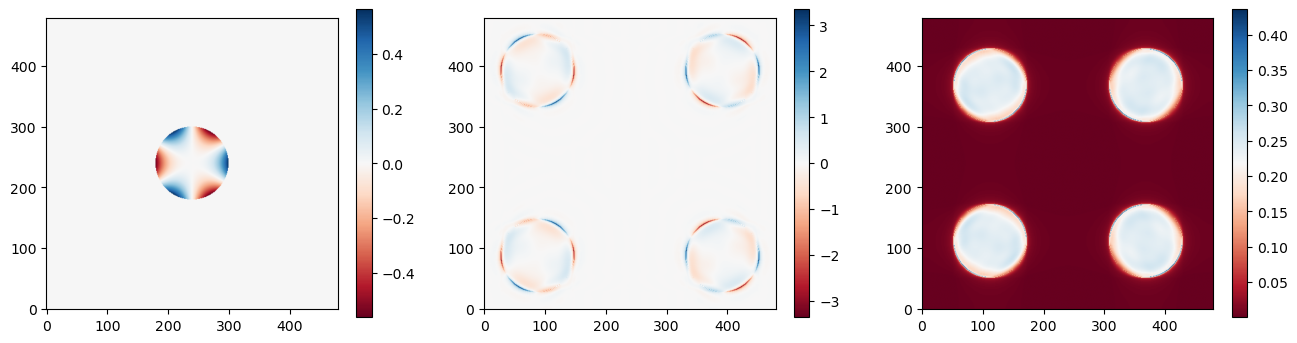

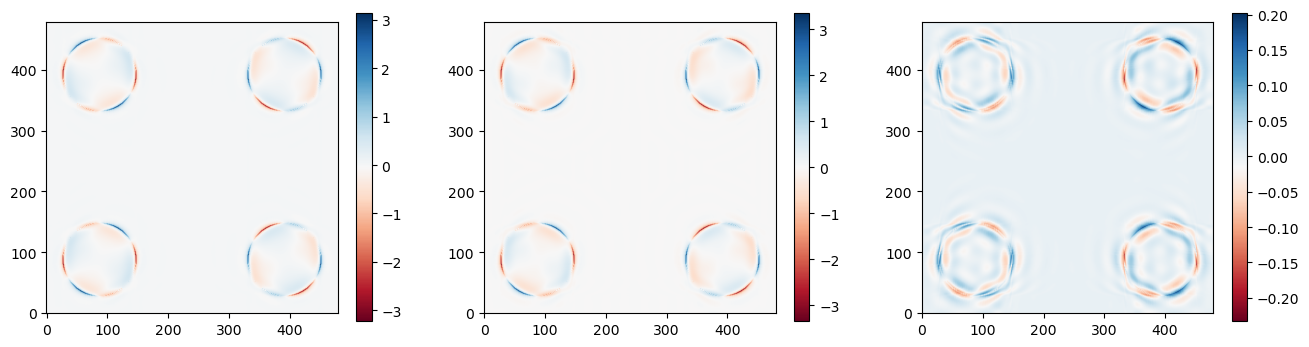

In [10]:
zern_phase = pupil.asTransmissionValue() * project_zernike_on_mask(pupil, 10, 0.2)
padded=zero_padding(zern_phase,oversampling)

# Perform the convolution using FFTs
fft_pupil = np.fft.fft2(padded)#np.fft.ifftshift(padded))
fft_ir = np.fft.fft2(ir)#np.fft.ifftshift(ir))
delta_I = (np.fft.ifft2(fft_pupil * fft_ir).real)
delta_I /= np.sum(pupil.asTransmissionValue())

fft_ir_ref = np.fft.fft2(ir_ref)#np.fft.ifftshift(ir_ref))
delta_I_ref = (np.fft.ifft2(fft_pupil * fft_ir_ref).real)
delta_I_ref /= np.sum(pupil.asTransmissionValue())
arr=pupil.asTransmissionValue()*np.exp(1j*zern_phase,dtype=complex)
pyr_image = pyr.get_intensity(arr,lambdaOverD)

plt.figure(figsize=(16,4))
plt.subplot(1,3,1)
plt.imshow(padded,origin='lower',cmap='RdBu')
plt.colorbar()
plt.subplot(1,3,2)
plt.imshow(delta_I_ref,origin='lower',cmap='RdBu')
plt.colorbar()
plt.subplot(1,3,3)
plt.imshow(pyr_image,origin='lower',cmap='RdBu')
plt.colorbar()

plt.figure(figsize=(16,4))
plt.subplot(1,3,1)
plt.imshow(delta_I,origin='lower',cmap='RdBu')
plt.colorbar()
plt.subplot(1,3,2)
plt.imshow(delta_I_ref,origin='lower',cmap='RdBu')
plt.colorbar()
plt.subplot(1,3,3)
plt.imshow(delta_I-delta_I_ref,origin='lower',cmap='RdBu')
plt.colorbar()

In [11]:
ir_fft = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(zero_padding(ir,oversampling))))
ir_fft_inv = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(zero_padding(ir,oversampling))))
ir_ref_fft = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(zero_padding(ir_ref,oversampling))))
ir_ref_fft_inv = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(zero_padding(ir_ref,oversampling))))

C:\Users\menes\AppData\Local\Temp\ipykernel_7696\1610323788.py:8: RuntimeWarning: invalid value encountered in divide
  og = norm/norm_ref
C:\Users\menes\AppData\Local\Temp\ipykernel_7696\1610323788.py:11: RuntimeWarning: invalid value encountered in divide
  og = (ir_fft * ir_ref_fft_inv) / (ir_ref_fft * ir_ref_fft_inv)
C:\Users\menes\AppData\Local\Temp\ipykernel_7696\1610323788.py:12: RuntimeWarning: divide by zero encountered in divide
  og2 = (ir_fft * ir_fft_inv) / (ir_ref_fft * ir_ref_fft_inv)
C:\Users\menes\AppData\Local\Temp\ipykernel_7696\1610323788.py:12: RuntimeWarning: invalid value encountered in divide
  og2 = (ir_fft * ir_fft_inv) / (ir_ref_fft * ir_ref_fft_inv)


(920.0, 1000.0)

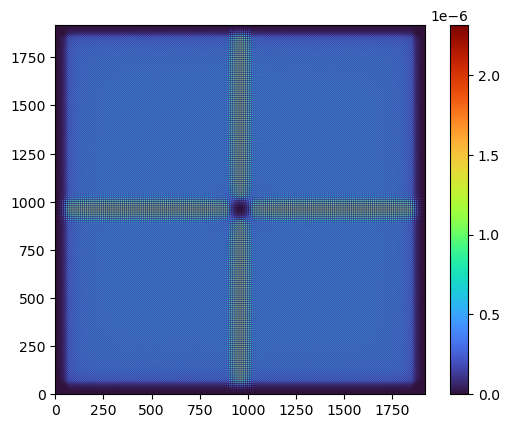

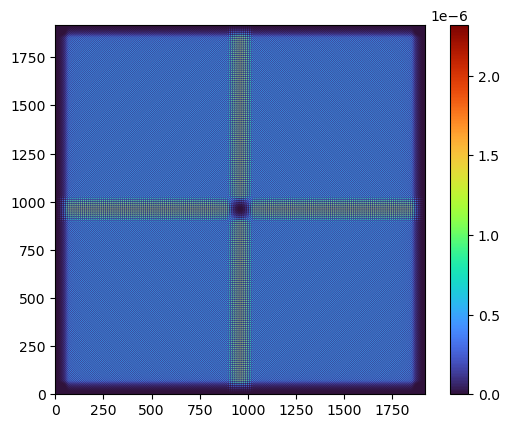

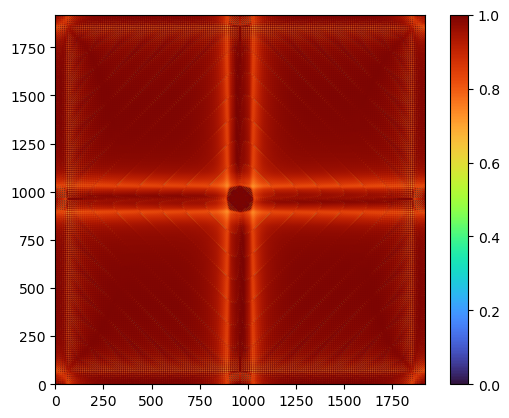

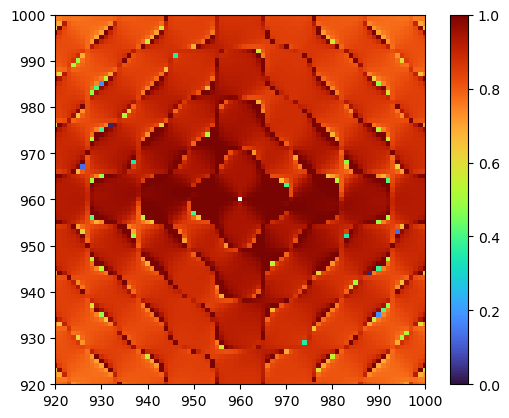

In [16]:
norm = ir_fft * np.conj(ir_ref_fft)
norm2 = ir_fft * np.conj(ir_fft)
norm_ref = ir_ref_fft * np.conj(ir_ref_fft)

norm /= np.sum(norm_ref)
norm_ref /= np.sum(norm_ref)

og = norm/norm_ref
# og = np.sqrt(norm2/norm_ref)

og = (ir_fft * ir_ref_fft_inv) / (ir_ref_fft * ir_ref_fft_inv)
og2 = (ir_fft * ir_fft_inv) / (ir_ref_fft * ir_ref_fft_inv)


plt.figure()
plt.imshow(np.abs(norm),origin='lower',cmap='turbo')
plt.colorbar()
# plt.xlim([920,1000])
# plt.ylim([920,1000])
# plt.xlim([900,1000])
# plt.ylim([900,1000])

plt.figure()
plt.imshow(np.abs(norm_ref),origin='lower',cmap='turbo')
plt.colorbar()

plt.figure()
plt.imshow(np.fft.fftshift(og.real),origin='lower',cmap='turbo',vmin=0,vmax=1)
plt.colorbar()


plt.figure()
plt.imshow(og2.real,origin='lower',cmap='turbo',vmin=0,vmax=1)
plt.colorbar()
plt.xlim([920,1000])
plt.ylim([920,1000])
# plt.xlim([120*3/2,120*5/2])
# plt.ylim([120*3/2,120*5/2])

d:\Program Files\miniconda3\envs\ekarus\Lib\site-packages\arte\math\toccd.py:39: RuntimeWarning: invalid value encountered in divide
  return rebinned / rebinned.sum() * set_total
d:\Program Files\miniconda3\envs\ekarus\Lib\site-packages\arte\math\toccd.py:39: RuntimeWarning: invalid value encountered in multiply
  return rebinned / rebinned.sum() * set_total


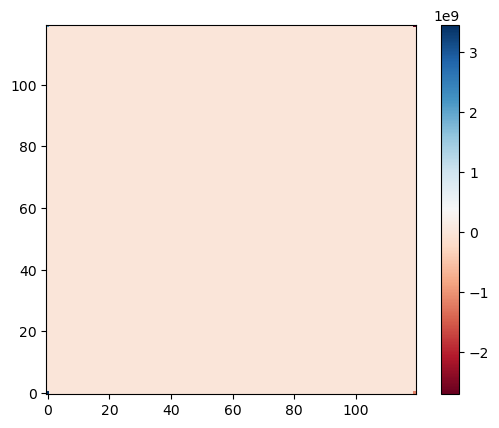

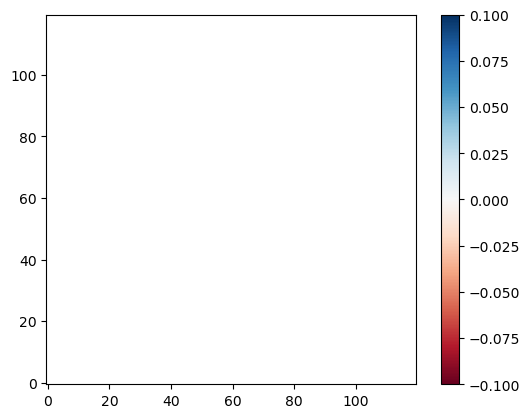

In [17]:
from arte.math.toccd import toccd

og2 = og2.real.copy()
og2[np.isnan(og2)] = 0

og = og.real.copy()
og[np.isnan(og)] = 0

ogs2 = toccd(og2,(Npix,Npix))
ogs = toccd(og,(Npix,Npix))

plt.figure()
plt.imshow(ogs,origin='lower',cmap='RdBu')
plt.colorbar()

plt.figure()
plt.imshow(ogs2,origin='lower',cmap='RdBu')
plt.colorbar()

In [18]:
# def estimate_og_from_psf(omega_turb, omega_dl, pyramid_mask):#, oversampling=4):
#     """
#     Computes 2D Optical Gains from PSFs (Omega) using the Convolutional Model.
#     """
#     def get_sensitivity(omega, mask):
#         # 1. Ensure Omega is normalized by its total flux (sum of intensities)
#         # This is critical for the ratio to be physically meaningful
#         omega_norm = omega / np.sum(omega)
        
#         # 2. Compute the IR in the Pupil Plane (Eq 13)
#         masked_omega = mask * omega_norm
        
#         # We need the Fourier Transform of the mask and the masked omega
#         # to find the sensitivity in the frequency domain.
#         m_fft = np.fft.fft2(np.fft.ifftshift(mask))
#         mo_fft = np.fft.fft2(np.fft.ifftshift(masked_omega))
        
#         # The WFS sensitivity S(f) is derived from the IR. 
#         # In Fourier Space, the sensitivity is:
#         # S = 2 * Im( conj(FFT(mask)) * FFT(mask * omega) )
#         # This is already a 2D map of frequencies.
#         S = 2 * np.imag(np.conj(m_fft) * mo_fft)
#         return S

#     # Compute 2D sensitivity maps
#     S_turb = get_sensitivity(omega_turb, pyramid_mask)
#     S_calib = get_sensitivity(omega_dl, pyramid_mask)
    
#     # 3. Compute the Optical Gain (Ratio of Sensitivities)
#     # Adding a small epsilon to avoid division by zero in dark zones
#     eps = np.max(np.abs(S_calib)) * 1e-4
#     og_2d = S_turb / (S_calib + eps)
    
#     # Return shifted for visualization (0 frequency at center)
#     return np.fft.fftshift(og_2d), np.fft.fftshift(S_turb), np.fft.fftshift(S_calib)

In [19]:
# gopt, sens, sens_ref = estimate_og_from_psf(omega,omega_ref,pyramid_mask)# compute_2d_optical_gains(ir, ir_ref)


# plt.figure(figsize=(16,4))
# plt.subplot(1,3,1)
# plt.imshow(np.fft.fft2(sens).real/np.fft.fft2(sens_ref).real,origin='lower',cmap='RdBu',vmin=0,vmax=1)
# plt.colorbar()
# plt.xlim([50,70])
# plt.ylim([50,70])
# plt.subplot(1,3,2)
# plt.imshow(np.fft.fft2(sens).real,origin='lower',cmap='RdBu')
# plt.colorbar()
# plt.subplot(1,3,3)
# plt.imshow(np.fft.fft2(sens_ref).real,origin='lower',cmap='RdBu')
# plt.colorbar()